APLICACIÓN BOX JENKINS

In [243]:
#Importación de librerías necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox

from pathlib import Path
from scipy.stats import probplot
from scipy.stats import jarque_bera

In [244]:
#Implementación de rutas relativas
direccion_base = Path.cwd().parent
direccion_datos = direccion_base / "Excel" 
direccion_raw = direccion_datos/ "Gold.xlsx"

In [245]:
#Creación de un DataFrame a partir del archivo Excel
data_base = pd.read_excel(direccion_raw)

In [246]:
#Información básica sobre los datos
data_base.info()

<class 'pandas.DataFrame'>
RangeIndex: 132 entries, 0 to 131
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Fecha   132 non-null    datetime64[us]
 1   Oro     132 non-null    int64         
dtypes: datetime64[us](1), int64(1)
memory usage: 2.2 KB


In [247]:
#Medidas de tendencia central y dispersión de la variable "Oro" 
data_base["Oro"].describe()

count     132.000000
mean     1385.454545
std       212.960928
min      1076.000000
25%      1236.250000
50%      1307.000000
75%      1537.000000
max      1969.000000
Name: Oro, dtype: float64

In [248]:
#Creación de una serie temporal a partir de la columna "Oro" del DataFrame
serie_gold = data_base.set_index("Fecha")["Oro"]

1. IDENTIFICACIÓN

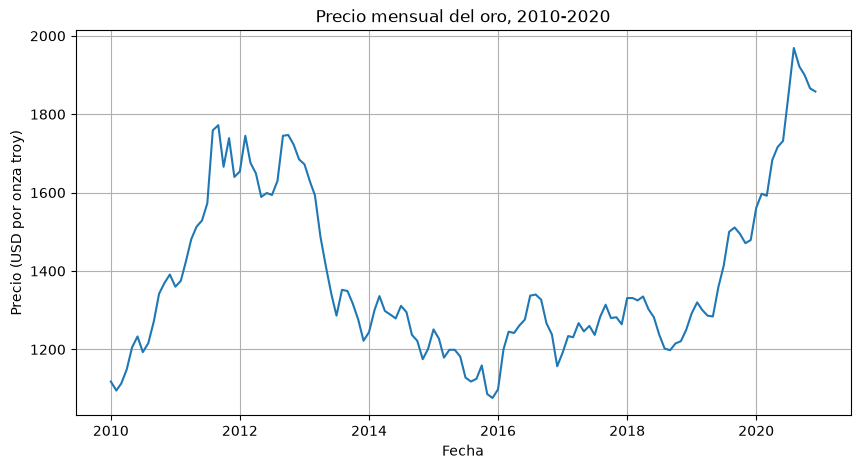

In [249]:
#Graficamos la serie de tiempo para observar su comportamiento a lo largo del tiempo
plt.figure(figsize=(10, 5))
plt.plot(serie_gold)
plt.title("Precio mensual del oro, 2010-2020")
plt.xlabel("Fecha")
plt.ylabel("Precio (USD por onza troy)")
plt.grid(True)
plt.show()

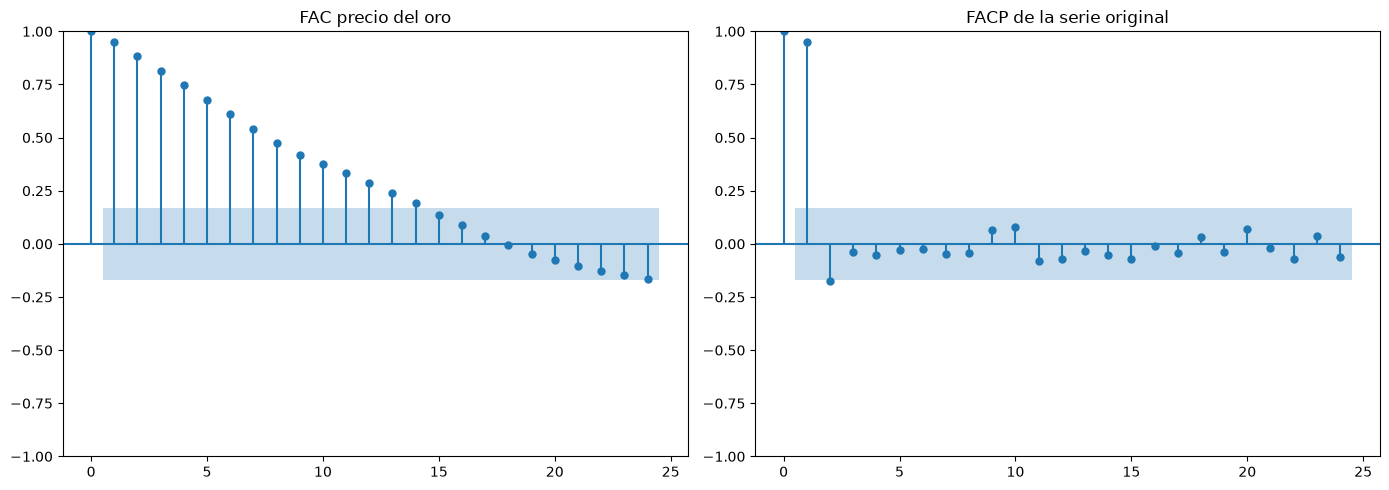

In [250]:
#Graficamos la FAC y FACP 
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_acf(
    serie_gold,
    lags=24,
    alpha=0.05,
    bartlett_confint=False,
    ax=axes[0]
)

axes[0].set_title("FAC precio del oro")

plot_pacf(
    serie_gold,
    lags=24,
    alpha=0.05,
    ax=axes[1]
)

axes[1].set_title("FACP de la serie original")

plt.tight_layout()
plt.show()

Pruebas de estacionariedad

In [251]:
#ADF
adf_resultado = adfuller(serie_gold)

In [252]:
print("=== Test ADF ===")
print("Estadístico ADF:", adf_resultado[0])
print("p-valor:", adf_resultado[1])
print("Rezagos usados:", adf_resultado[2]) 
print("Observaciones:", adf_resultado[3])
print("Valores críticos:")
for nivel, valor in adf_resultado[4].items():
    print(f"{nivel}: {valor}")

if adf_resultado[1] < 0.05:
    print("ADF: Rechazamos H0. Según el test, la serie es estacionaria.")
else:
    print("ADF: No rechazamos H0. Según el test, la serie no es estacionaria.")

=== Test ADF ===
Estadístico ADF: -1.2648867996121214
p-valor: 0.6450797001261268
Rezagos usados: 1
Observaciones: 130
Valores críticos:
1%: -3.4816817173418295
5%: -2.8840418343195267
10%: -2.578770059171598
ADF: No rechazamos H0. Según el test, la serie no es estacionaria.


In [253]:
#KPSS
kpss_resultado = kpss(serie_gold, regression="c", nlags="auto")

C:\Users\Usuario\AppData\Local\Temp\ipykernel_11648\4101538916.py:2: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_resultado = kpss(serie_gold, regression="c", nlags="auto")


In [254]:
print("\n=== Test KPSS ===")
print("Estadístico KPSS:", kpss_resultado[0])
print("p-valor:", kpss_resultado[1])
print("Rezagos usados:", kpss_resultado[2])
print("Valores críticos:")
for nivel, valor in kpss_resultado[3].items():
    print(f"{nivel}: {valor}")

if kpss_resultado[1] < 0.05:
    print("KPSS: rechazamos H0. Según el test, la serie es no estacionaria.")
else:
    print("KPSS: no rechazamos H0. Según el test, La serie es estacionaria.")


=== Test KPSS ===
Estadístico KPSS: 0.2504776443403076
p-valor: 0.1
Rezagos usados: 6
Valores críticos:
10%: 0.347
5%: 0.463
2.5%: 0.574
1%: 0.739
KPSS: no rechazamos H0. Según el test, La serie es estacionaria.


Creación de la serie diferenciada

In [255]:
#Creamos una nueva serie temporal que representa la primera diferencia de la serie original
serie_diff = serie_gold.diff().dropna()

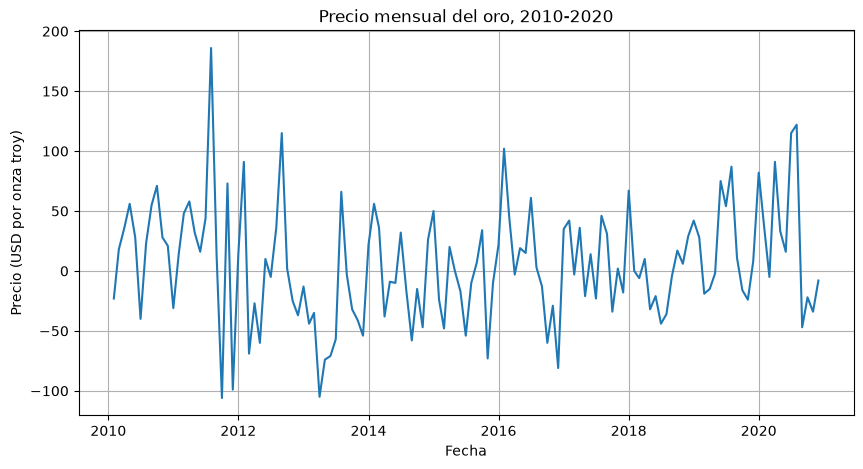

In [256]:
plt.figure(figsize=(10, 5))
plt.plot(serie_diff)
plt.title("Precio mensual del oro, 2010-2020")
plt.xlabel("Fecha")
plt.ylabel("Precio (USD por onza troy)")
plt.grid(True)
plt.show()

In [257]:
#Volvemos a probar la estacionariedad con ADF
adf_resultado_diff = adfuller(serie_diff)

In [258]:
print("=== Test ADF ===")
print("Estadístico ADF:", adf_resultado_diff[0])
print("p-valor:", adf_resultado_diff[1])
print("Rezagos usados:", adf_resultado_diff[2]) 
print("Observaciones:", adf_resultado_diff[3])
print("Valores críticos:")
for nivel, valor in adf_resultado_diff[4].items():
    print(f"{nivel}: {valor}")

if adf_resultado_diff[1] < 0.05:
    print("ADF: Rechazamos H0. Según el test, la serie es estacionaria.")
else:
    print("ADF: No rechazamos H0. Según el test, la serie no es estacionaria.")

=== Test ADF ===
Estadístico ADF: -8.896999071489738
p-valor: 1.199430006448276e-14
Rezagos usados: 0
Observaciones: 130
Valores críticos:
1%: -3.4816817173418295
5%: -2.8840418343195267
10%: -2.578770059171598
ADF: Rechazamos H0. Según el test, la serie es estacionaria.


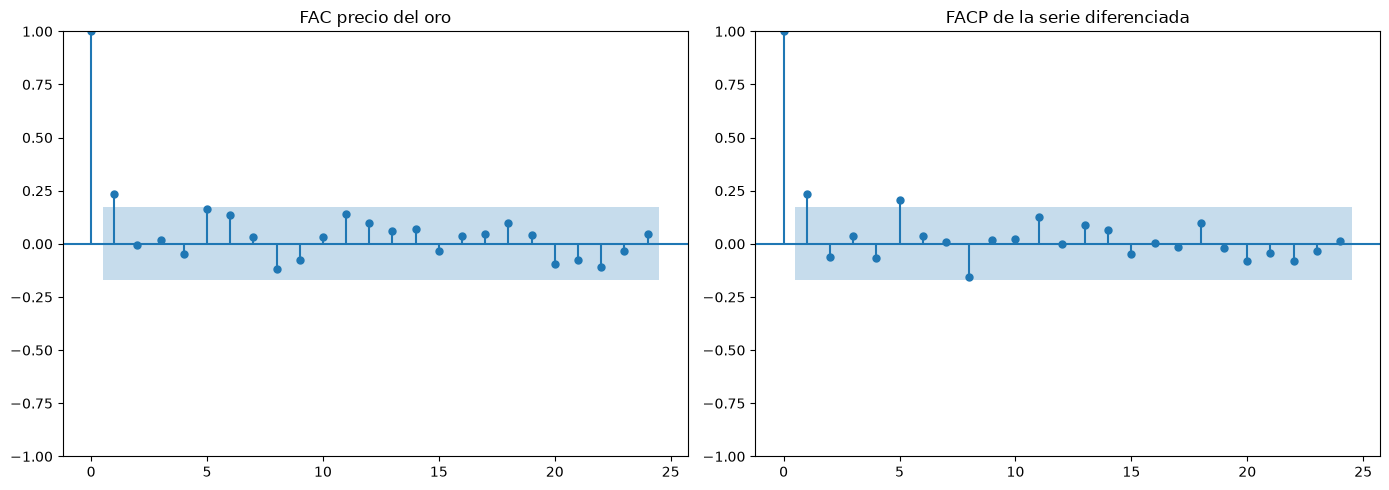

In [259]:
#Graficamos la FAC y FACP de la serie diferenciada
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_acf(
    serie_diff,
    lags=24,
    alpha=0.05,
    bartlett_confint=False,
    ax=axes[0]
)

axes[0].set_title("FAC precio del oro")

plot_pacf(
    serie_diff,
    lags=24,
    alpha=0.05,
    ax=axes[1]
)

axes[1].set_title("FACP de la serie diferenciada")

plt.tight_layout()
plt.show()

Selección del modelo apropiado

In [260]:
modelos = {
    "ARIMA(1,1,0)": (1,1,0),
    "ARIMA(0,1,1)": (0,1,1),
    "ARIMA(1,1,1)": (1,1,1),
}

for nombre, orden in modelos.items():
    res = ARIMA(serie_gold, order=orden).fit()
    print(nombre, "AIC:", round(res.aic,2), "BIC:", round(res.bic,2))
    print(acorr_ljungbox(res.resid, lags=[10, 20]))
    print(res.summary().tables[1])

c:\Users\Usuario\anaconda3\anaconda\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\Usuario\anaconda3\anaconda\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\Usuario\anaconda3\anaconda\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\Usuario\anaconda3\anaconda\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\Usuario\anaconda3\anaconda\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information 

ARIMA(1,1,0) AIC: 1385.25 BIC: 1391.0
     lb_stat  lb_pvalue
10  0.653007   0.999976
20  4.809602   0.999795
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2461      0.077      3.180      0.001       0.094       0.398
sigma2      2220.3265    226.144      9.818      0.000    1777.092    2663.561
ARIMA(0,1,1) AIC: 1384.57 BIC: 1390.33
     lb_stat  lb_pvalue
10  0.782642   0.999945
20  4.998423   0.999723
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1          0.2724      0.075      3.614      0.000       0.125       0.420
sigma2      2208.6582    224.013      9.860      0.000    1769.601    2647.716
ARIMA(1,1,1) AIC: 1384.58 BIC: 1393.2
     lb_stat  lb_pvalue
10  0.776823   0.999947
20  5.305533   0.999562
                 coef    std err     

c:\Users\Usuario\anaconda3\anaconda\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\Usuario\anaconda3\anaconda\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\Usuario\anaconda3\anaconda\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


De acuerdo a lo anterior se pueden escoger los modelos ARIMA (1,1,0) o ARIMA (0,1,1). Estos dos son equivalentes.

ESTIMACIÓN

In [261]:
modelo_MA1 = SARIMAX(
    serie_gold,
    order=(0, 1, 1),
    trend="n",
    enforce_stationarity=False,
    enforce_invertibility=False
)

c:\Users\Usuario\anaconda3\anaconda\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\Usuario\anaconda3\anaconda\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [262]:
type(modelo_MA1)

statsmodels.tsa.statespace.sarimax.SARIMAX

In [263]:
estimacion_MA1 = modelo_MA1.fit(disp=False)

In [264]:
estimacion_MA1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:                    Oro   No. Observations:                  132
Model:               SARIMAX(0, 1, 1)   Log Likelihood                -680.477
Date:                Wed, 21 Oct 2026   AIC                           1364.955
Time:                        18:42:00   BIC                           1370.674
Sample:                    01-01-2010   HQIC                          1367.279
                         - 12-01-2020                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1          0.2751      0.076      3.615      0.000       0.126       0.424
sigma2      2235.2521    229.799      9.727      0.000    1784.855    2685.649
===================================================================================
Ljung-Box (L1) (Q):                   0.04   Jarque-Bera (JB):                 5.84
Prob(Q):                              0.84   Prob(JB):                         0.05
Heteroskedasticity (H):               0.51   Skew:                             0.30
Prob(H) (two-sided):                  0.03   Kurtosis:                         3.85
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

VALIDACIÓN DE SUPUESTOS

In [265]:
#Sacamos las residuales del modelo
residuales = estimacion_MA1.resid.dropna()

In [266]:
type(residuales)

pandas.Series

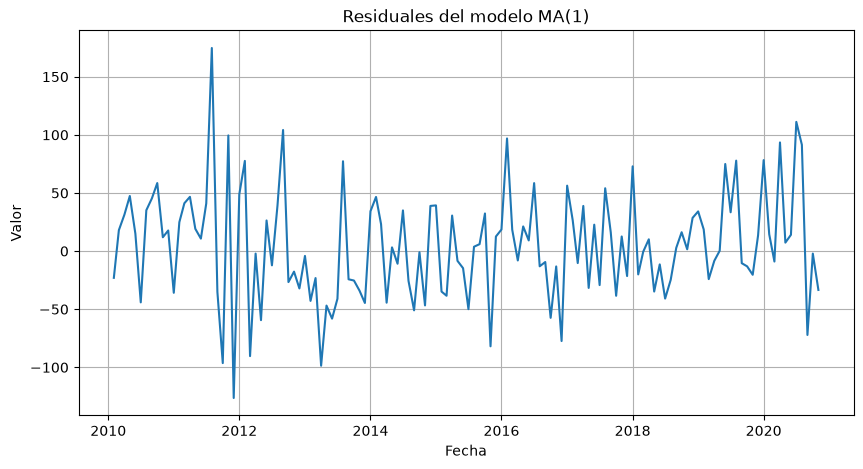

In [267]:
#Graficamos las residuales del modelo
plt.figure(figsize=(10, 5))
plt.plot(residuales.iloc[1:-1])
plt.title("Residuales del modelo MA(1)")
plt.xlabel("Fecha")
plt.ylabel("Valor")
plt.grid(True)
plt.show()

In [268]:
residuales.describe()

count     132.000000
mean       12.833092
std       107.625101
min      -126.373621
25%       -25.401297
50%         3.009982
75%        33.577720
max      1118.000000
dtype: float64

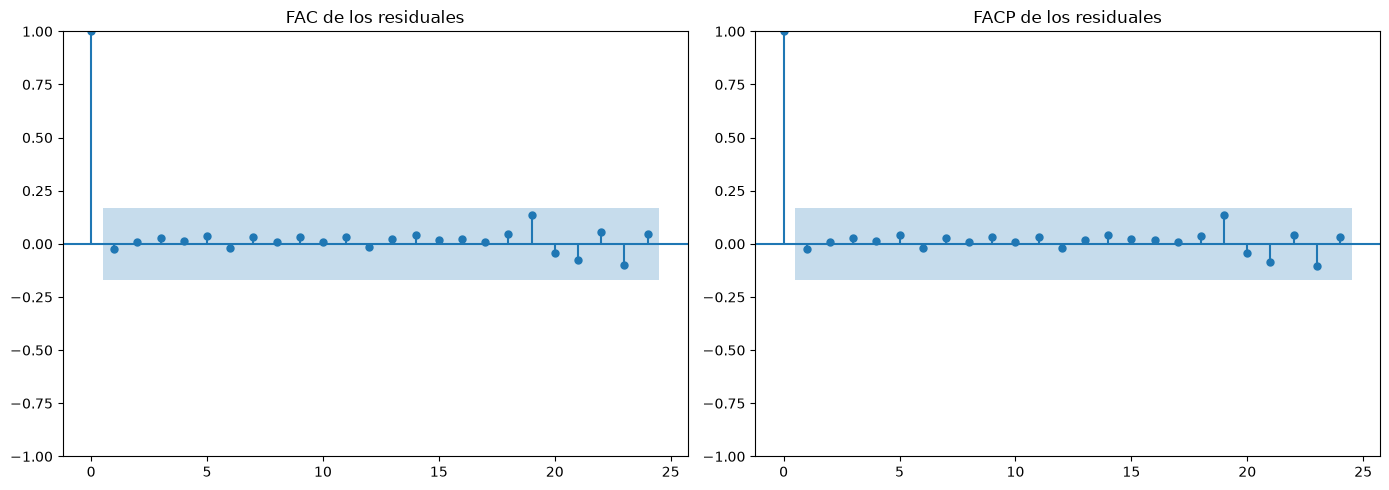

In [269]:
#Graficamos la FAC y FACP de los residuales del modelo
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_acf(
    residuales,
    lags=24,
    alpha=0.05,
    bartlett_confint=False,
    ax=axes[0]
)

axes[0].set_title("FAC de los residuales")

plot_pacf(
    residuales,
    lags=24,
    alpha=0.05,
    ax=axes[1]
)

axes[1].set_title("FACP de los residuales")

plt.tight_layout()
plt.show()

In [270]:
#Realizamos la prueba de Ljung-Box para evaluar la autocorrelación de los residuales del modelo
ljung_box = acorr_ljungbox(
    residuales,
    lags=[6, 12, 18, 24],
    return_df=True
)

ljung_box

,lb_stat,lb_pvalue
6,0.481038,0.998062
12,0.986194,0.999987
18,1.787046,1.000000
24,8.280541,0.998780


In [271]:
#Realizamos la prueba de heterocedasticidad ARCH para evaluar la presencia de heterocedasticidad
arch_test = het_arch(residuales, nlags=12) 

print("Prueba ARCH")
print("LM statistic:", arch_test[0])
print("LM p-value:", arch_test[1])

Prueba ARCH
LM statistic: 13.695492325387569
LM p-value: 0.32057477105374177


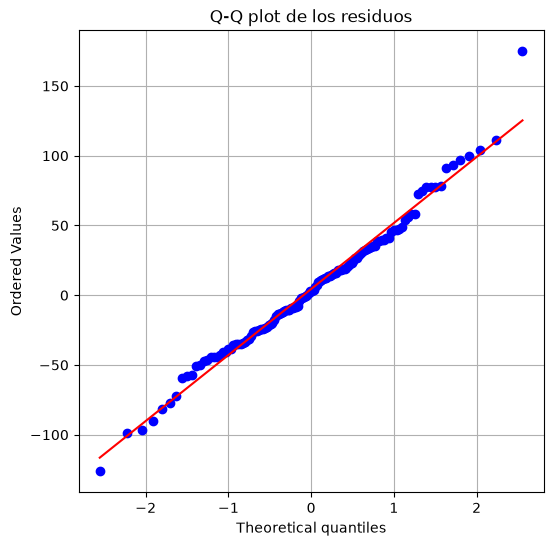

In [272]:
# Graficamos el Q-Q plot de los residuos para evaluar la normalidad
plt.figure(figsize=(6, 6))
probplot(residuales.iloc[1:-1], dist="norm", plot=plt)
plt.title("Q-Q plot de los residuos")
plt.grid(True)
plt.show()

In [273]:
#Realizamos la prueba de Jarque-Bera para evaluar la normalidad de los residuales del modelo
jb_test = jarque_bera(residuales.iloc[1:-1])

print("Prueba Jarque-Bera")
print("Jarque-Bera statistic:", jb_test.statistic)
print("Jarque-Bera p-value:", jb_test.pvalue)

Prueba Jarque-Bera
Jarque-Bera statistic: 5.999617927155267
Jarque-Bera p-value: 0.04979658041983031


PRONOSTICO

In [274]:
#Realizamos el pronóstico a 12 pasos del modelo
pronostico = estimacion_MA1.get_forecast(steps=12)

In [275]:
#Obtenemos el pronóstico puntual, la varianza del pronóstico y los intervalos de confianza
pronostico_puntual = pronostico.predicted_mean
varianza_pronostico = pronostico.var_pred_mean
intervalos = pronostico.conf_int()

In [276]:
#Creamos un DataFrame con el pronóstico puntual y los intervalos de confianza
tabla_pronostico = pd.DataFrame({
    "pronostico": pronostico_puntual,
    "limite_inferior": intervalos.iloc[:, 0],
    "limite_superior": intervalos.iloc[:, 1]
})


In [277]:
tabla_pronostico

,pronostico,limite_inferior,limite_superior
2021-01-01,1858.32745,1765.663384,1950.991515
2021-02-01,1858.32745,1708.169817,2008.485082
2021-03-01,1858.32745,1667.256782,2049.398118
2021-04-01,1858.32745,1633.675083,2082.979816
2021-05-01,1858.32745,1604.498036,2112.156863
2021-06-01,1858.32745,1578.345206,2138.309694
2021-07-01,1858.32745,1554.434800,2162.220099
2021-08-01,1858.32745,1532.273117,2184.381783
2021-09-01,1858.32745,1511.524748,2205.130151
2021-10-01,1858.32745,1491.949504,2224.705395


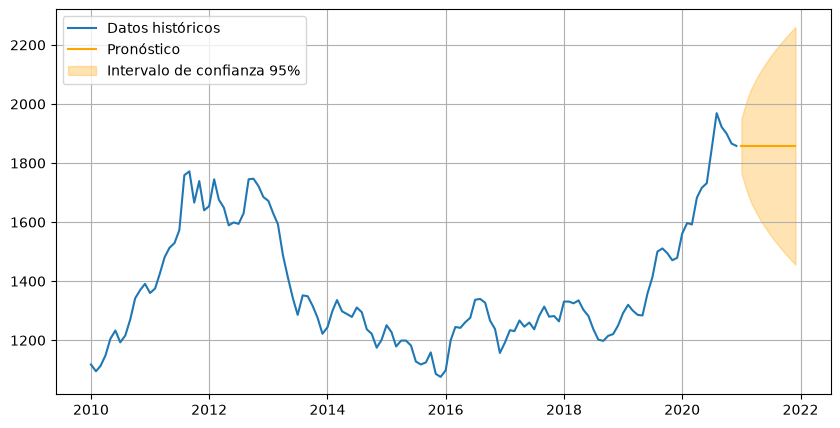

In [278]:
#Graficamos el pronóstico puntual y los intervalos de confianza junto con los datos históricos
plt.figure(figsize=(10, 5))
plt.plot(serie_gold, label="Datos históricos")
plt.plot(pronostico_puntual, label="Pronóstico", color="orange")
plt.fill_between(
    pronostico_puntual.index,
    intervalos.iloc[:, 0],
    intervalos.iloc[:, 1],
    color="orange",
    alpha=0.3,
    label="Intervalo de confianza 95%"
)
plt.legend()
plt.grid(True)
plt.show()